# Loan Default ML Project

**📝 Problem Statement**

* A bank wants to predict whether a loan applicant is likely to default on their loan. 
* The bank has information about the applicant's income, loan amount, credit history, employment details, and other financial characteristics. 
* The goal is to identify applicants who are likely to default so the bank can make better lending decisions.

**Step 1: Import Libraries**

In [12]:
# data handling 
import pandas as pd
import numpy as np
import joblib

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# feature selection
from sklearn.feature_selection import VarianceThreshold

# classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# metrics
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

**Step 2: Load Dataset**

In [13]:
df = pd.read_csv("Loan_Default.csv")

**Step 3: Understand Your Data (EDA)**

In [4]:
df.head()

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


In [4]:
df.sample(5)

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
37978,62868,2019,cf,Male,nopre,type2,p3,l1,nopc,b/c,...,CIB,840,CIB,35-44,to_inst,70.833333,North,direct,0,25.0
28837,53727,2019,cf,Male,nopre,type1,p3,l1,nopc,nob/c,...,EXP,512,CIB,35-44,not_inst,35.047847,North,direct,0,43.0
128527,153417,2019,cf,Sex Not Available,nopre,type1,p3,l2,nopc,nob/c,...,CIB,695,CIB,45-54,to_inst,80.957944,south,direct,0,44.0
140921,165811,2019,cf,Female,nopre,type1,p1,l1,nopc,nob/c,...,CRIF,719,CIB,35-44,not_inst,93.545082,North,direct,1,13.0
26023,50913,2019,cf,Female,nopre,type3,p3,l1,nopc,nob/c,...,CRIF,615,CIB,65-74,not_inst,68.958869,North,direct,0,48.0


In [5]:
df.columns

Index(['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type',
       'loan_purpose', 'Credit_Worthiness', 'open_credit',
       'business_or_commercial', 'loan_amount', 'rate_of_interest',
       'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization',
       'interest_only', 'lump_sum_payment', 'property_value',
       'construction_type', 'occupancy_type', 'Secured_by', 'total_units',
       'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type',
       'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type',
       'Status', 'dtir1'],
      dtype='str')

In [6]:
df.dtypes

ID                             int64
year                           int64
loan_limit                       str
Gender                           str
approv_in_adv                    str
loan_type                        str
loan_purpose                     str
Credit_Worthiness                str
open_credit                      str
business_or_commercial           str
loan_amount                    int64
rate_of_interest             float64
Interest_rate_spread         float64
Upfront_charges              float64
term                         float64
Neg_ammortization                str
interest_only                    str
lump_sum_payment                 str
property_value               float64
construction_type                str
occupancy_type                   str
Secured_by                       str
total_units                      str
income                       float64
credit_type                      str
Credit_Score                   int64
co-applicant_credit_type         str
a

In [7]:
df.nunique()

ID                           148670
year                              1
loan_limit                        2
Gender                            4
approv_in_adv                     2
loan_type                         3
loan_purpose                      4
Credit_Worthiness                 2
open_credit                       2
business_or_commercial            2
loan_amount                     211
rate_of_interest                131
Interest_rate_spread          22516
Upfront_charges               58271
term                             26
Neg_ammortization                 2
interest_only                     2
lump_sum_payment                  2
property_value                  385
construction_type                 2
occupancy_type                    3
Secured_by                        2
total_units                       4
income                         1001
credit_type                       4
Credit_Score                    401
co-applicant_credit_type          2
age                         

**Step 4: Data Cleaning**

In [5]:
# 1. check missing values
df.isnull().sum()

ID                               0
year                             0
loan_limit                    3344
Gender                           0
approv_in_adv                  908
loan_type                        0
loan_purpose                   134
Credit_Worthiness                0
open_credit                      0
business_or_commercial           0
loan_amount                      0
rate_of_interest             36439
Interest_rate_spread         36639
Upfront_charges              39642
term                            41
Neg_ammortization              121
interest_only                    0
lump_sum_payment                 0
property_value               15098
construction_type                0
occupancy_type                   0
Secured_by                       0
total_units                      0
income                        9150
credit_type                      0
Credit_Score                     0
co-applicant_credit_type         0
age                            200
submission_of_applic

In [14]:
# 2. remove duplicates
print("duplicate values: ",df.duplicated().sum())
df = df.drop_duplicates()

duplicate values:  0


In [15]:
# 3. remove unwanted cols
df.drop(columns=['ID'], inplace=True)

In [16]:
df.drop(columns=['year'], inplace=True)

In [17]:
# 4. fix col names
df = df.rename(columns= {
    'Gender': 'gender',
    'Credit_Worthiness': 'credit_worthiness',
    'Interest_rate_spread': 'interest_rate_spread',
    'Upfront_charges': 'upfront_charges',
    'term': 'loan_term_months',
    'Neg_ammortization': 'negative_amortization',
    'Secured_by': 'secured_by',
    'Credit_Score': 'credit_score',
    'Region': 'region',
    'Security_Type': 'security_type',
    'Status': 'status',
    'dtir1': 'debt_to_income_ratio'
})


In [12]:
# 5. fix data types
# no need

<Axes: >

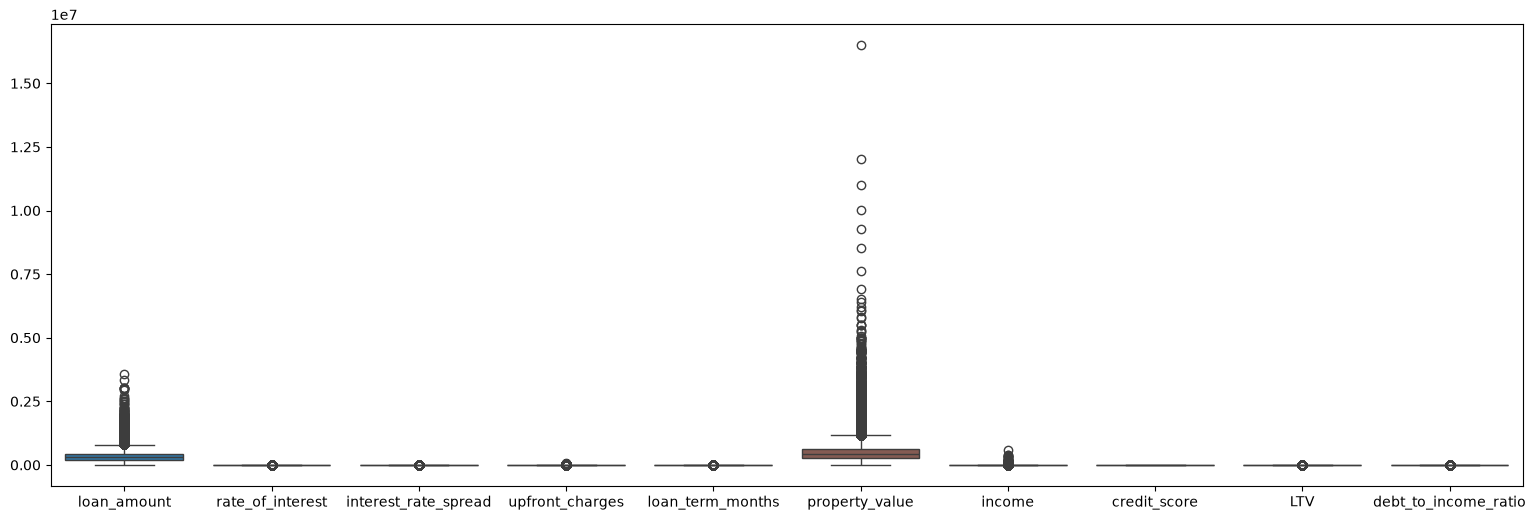

In [10]:
# 6. remove outliers
plt.figure(figsize=(19,6))
sns.boxplot(df[df.select_dtypes(include=[int,float]).drop(columns=['status']).columns.to_list()])

In [18]:
cols = df.select_dtypes(include=[int,float]).drop(columns=['status']).columns.to_list()
for i,col in enumerate(cols, start=1):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    before_outliers = df[(df[col] < lower) | (df[col] > upper)]
    df[col] = df[col].clip(lower,upper)
    after_outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\n{i}. {col}")
    print(f"before outliers: {len(before_outliers)}")
    print(f"after outliers: {len(after_outliers)}")


1. loan_amount
before outliers: 1895
after outliers: 0

2. rate_of_interest
before outliers: 856
after outliers: 0

3. interest_rate_spread
before outliers: 445
after outliers: 0

4. upfront_charges
before outliers: 2880
after outliers: 0

5. loan_term_months
before outliers: 26944
after outliers: 0

6. property_value
before outliers: 5266
after outliers: 0

7. income
before outliers: 6546
after outliers: 0

8. credit_score
before outliers: 0
after outliers: 0

9. LTV
before outliers: 1882
after outliers: 0

10. debt_to_income_ratio
before outliers: 2013
after outliers: 0


**Step 5: Feature Engineering**

In [19]:
df["loan_income_ratio"] = df["loan_amount"] / (df["income"] + 1)

df["property_loan_ratio"] = df["loan_amount"] / (df["property_value"] + 1)

df["credit_risk"] = pd.cut(
    df["credit_score"],
    bins=[0, 580, 670, 740, 800, 900],
    labels=["Poor", "Fair", "Good", "Very Good", "Excellent"]
)

df["high_loan"] = (df["loan_amount"] > df["loan_amount"].median()).astype(int)

**Step 6: Data Visualization**

Univariate:

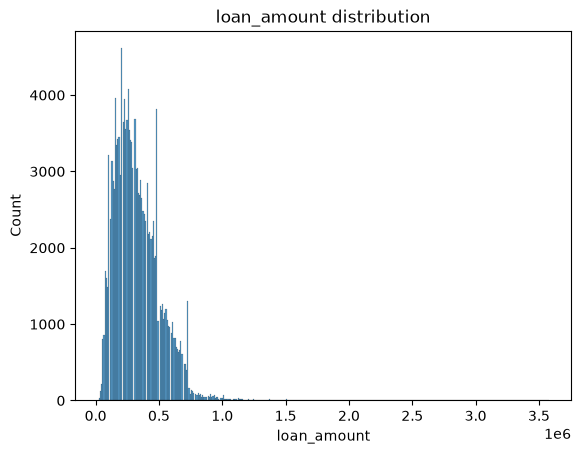

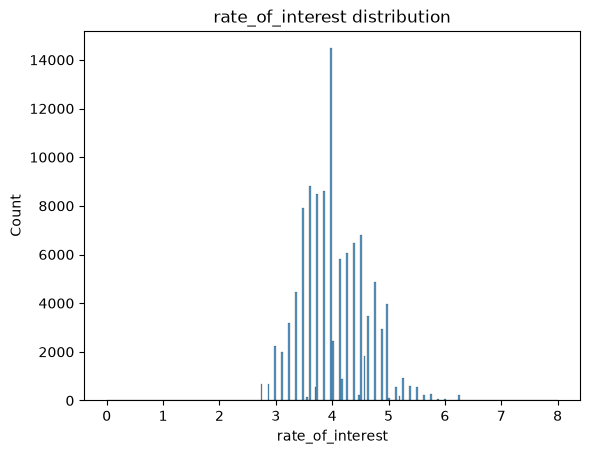

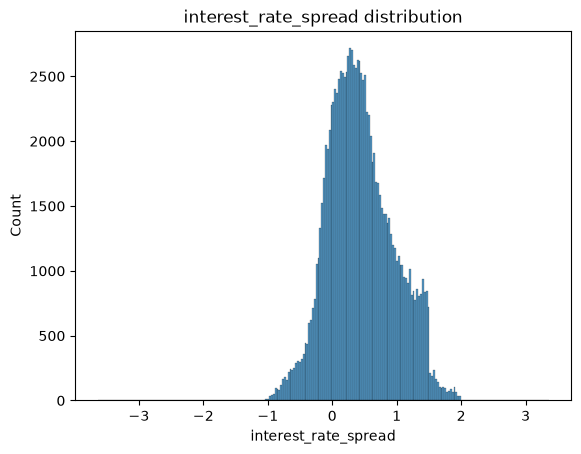

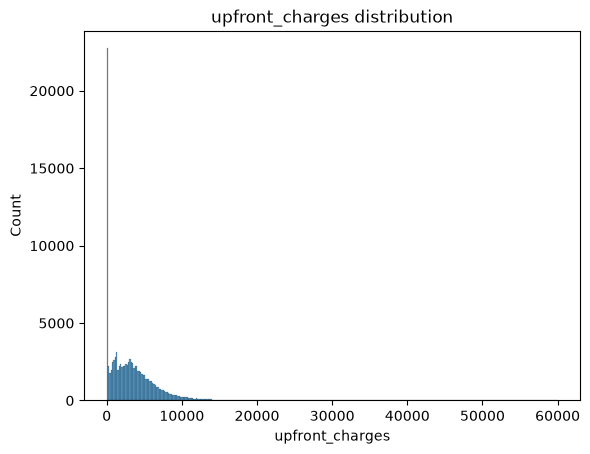

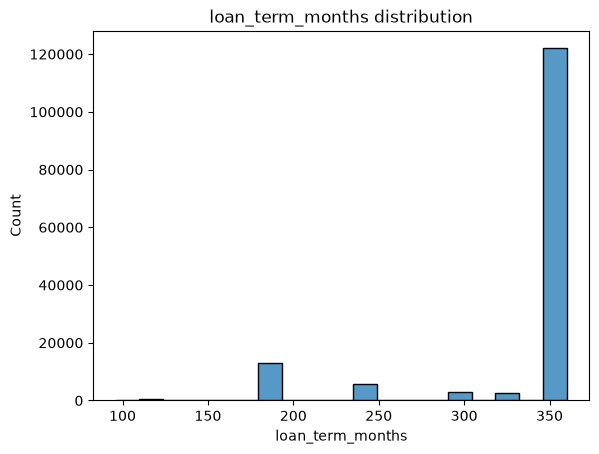

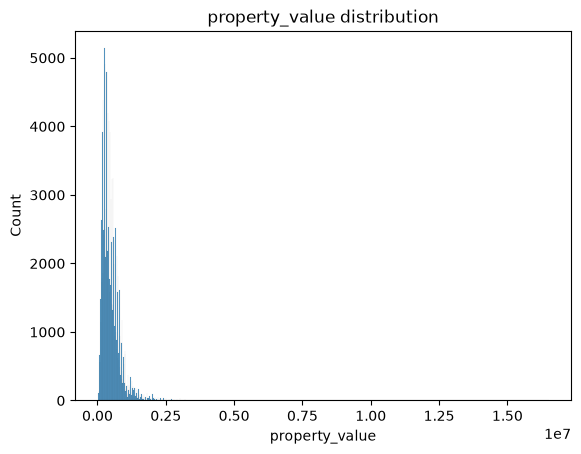

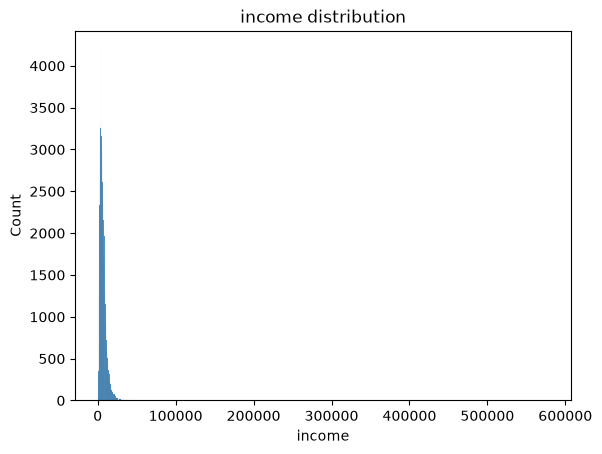

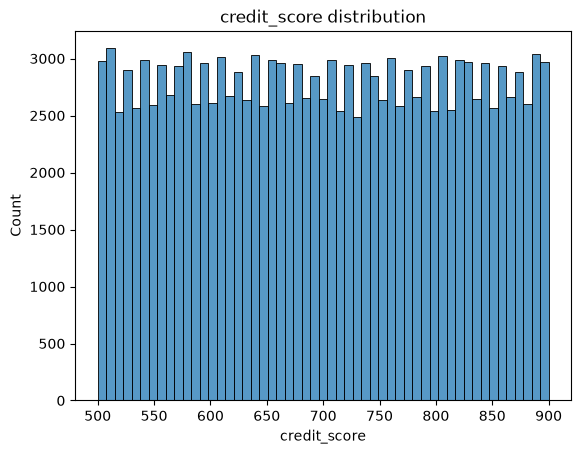

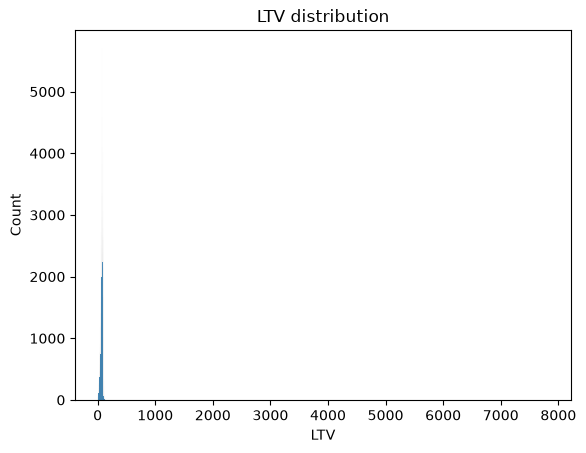

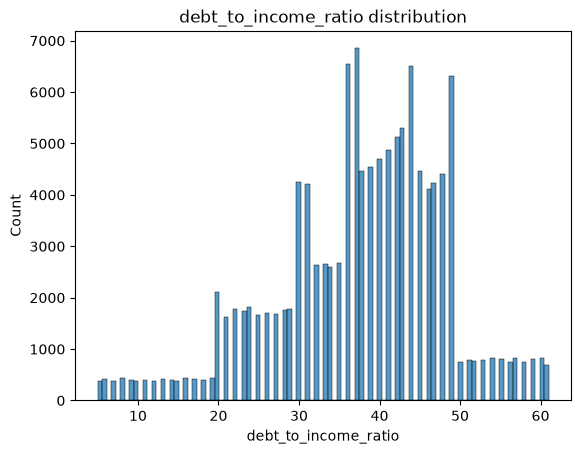

In [15]:
nums = ['loan_amount','rate_of_interest','interest_rate_spread','upfront_charges','loan_term_months',
        'property_value','income','credit_score','LTV','debt_to_income_ratio']
for n in nums:
    sns.histplot(data=df, x=n)
    plt.title(f"{n} distribution")
    plt.show()

In [ ]:
cats = ['year', 'loan_limit', 'gender', 'approv_in_adv', 'loan_type',
       'loan_purpose', 'credit_worthiness', 'open_credit',
       'business_or_commercial', 'negative_amortization', 'interest_only', 'lump_sum_payment',
        'construction_type', 'occupancy_type', 'secured_by',
       'total_units', 'credit_type', 'co-applicant_credit_type', 'age', 'submission_of_application', 
       'region', 'security_type', 'status', 'credit_risk', 'high_loan']
for n in nums:
    sns.countplot(data=df, x=n)
    plt.title(f"{n} distribution")
    plt.show()

Bivariate & Multivariate:

In [ ]:
nums = ['loan_amount','rate_of_interest','interest_rate_spread','upfront_charges','loan_term_months',
        'property_value','income','credit_score','LTV','debt_to_income_ratio']
for n in nums:
    sns.barplot(data=df, x=n, y='Status')
    plt.title(f"{n} distribution")
    plt.show()

In [ ]:
cats = ['year', 'loan_limit', 'gender', 'approv_in_adv', 'loan_type',
       'loan_purpose', 'credit_worthiness', 'open_credit',
       'business_or_commercial', 'negative_amortization', 'interest_only', 'lump_sum_payment',
        'construction_type', 'occupancy_type', 'secured_by',
       'total_units', 'credit_type', 'co-applicant_credit_type', 'age', 'submission_of_application', 
       'region', 'security_type','credit_risk', 'high_loan']
for n in nums:
    sns.countplot(data=df, x=n)
    plt.title(f"{n} distribution")
    plt.show()

Correlation analysis:

<Axes: >

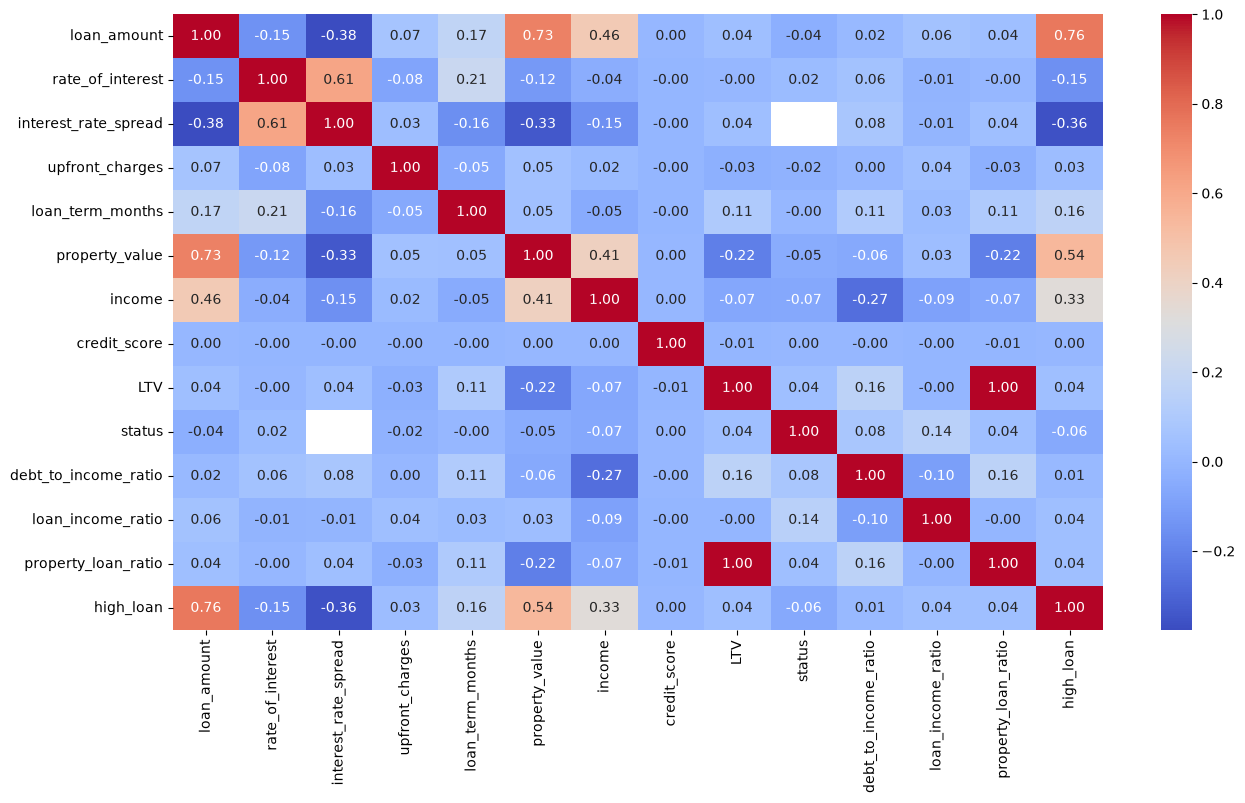

In [21]:
plt.figure(figsize=(15,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")

**Step 7: Define Features (X) and Target (y)**

In [20]:
X = df.drop(columns=['status'])
y = df['status']

num_cols = df.select_dtypes(include=[int,float]).drop(columns=['status']).columns.to_list()
cat_cols = df.select_dtypes(include=[str,'object']).columns.to_list()

**Step 8: Train-Test Split**

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (118936, 35) | X_test: (29734, 35)


**Step 9: Preprocessing Pipeline**

In [23]:
num_trans = Pipeline([
    ("imp",SimpleImputer(strategy="mean")),
    ('scr',StandardScaler())
])

cat_trans = Pipeline([
    ('imp',SimpleImputer(strategy="most_frequent")),
    ('ohe',OneHotEncoder(sparse_output=False, handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ('num_pre',num_trans,num_cols),
    ('cat_pre',cat_trans,cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.fit_transform(X_test)

In [24]:
X_train_df = pd.DataFrame(X_train_processed, columns=preprocessor.get_feature_names_out())
X_test_df = pd.DataFrame(X_test_processed, columns=preprocessor.get_feature_names_out())

**Step 10: Feature Selection**

In [25]:
selector = VarianceThreshold(threshold=0.01)
X_train_sele = selector.fit_transform(X_train_df)
X_test_sele = selector.transform(X_test_df)
print("X_train shape before feature selection: ",X_train_df.shape)
print("X_train shape after feature selection: ",X_train_sele.shape)
print("\nX_test shape before feature selection: ",X_test_df.shape)
print("X_test shape after feature selection: ",X_test_sele.shape)

X_train shape before feature selection:  (118936, 72)
X_train shape after feature selection:  (118936, 58)

X_test shape before feature selection:  (29734, 72)
X_test shape after feature selection:  (29734, 58)


**Step 11 & 12: Train Models & Regression Metrics**

In [ ]:
models = {
    "Logistic" : LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_split=5, min_samples_leaf=4),
    "Random forest": RandomForestClassifier(n_estimators=300, max_depth=9, min_samples_split=6, min_samples_leaf=4),
    "Naive bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVM": SVC(C=0.01, kernel="rbf", gamma="scale"),
    "xgboost": XGBClassifier(learning_rate=0.01, n_estimators=350, max_depth=8)
}

for name,model in models.items():
    model.fit(X_train_sele,y_train)
    y_pred = model.predict(X_test_sele)
    
    acc = accuracy_score(y_test,y_pred)
    f1 = f1_score(y_test, y_pred)
    ps = precision_score(y_test, y_pred)
    rs = recall_score(y_test, y_pred)
    
    print(f"[{name}] -> accuracy: {acc*100:.2f} | f1_score: {f1:.2f} | precision: {ps:.2f} | recall: {rs:.2f}")

[Logistic] -> accuracy: 87.28 | f1_score: 0.66 | precision: 0.94 | recall: 0.51
[Decision Tree] -> accuracy: 100.00 | f1_score: 1.00 | precision: 1.00 | recall: 1.00
[Random forest] -> accuracy: 100.00 | f1_score: 1.00 | precision: 1.00 | recall: 1.00
[Naive bayes] -> accuracy: 96.76 | f1_score: 0.93 | precision: 1.00 | recall: 0.87
[KNN] -> accuracy: 92.95 | f1_score: 0.85 | precision: 0.88 | recall: 0.82
[SVM] -> accuracy: 86.74 | f1_score: 0.63 | precision: 1.00 | recall: 0.46
[xgboost] -> accuracy: 100.00 | f1_score: 1.00 | precision: 1.00 | recall: 1.00


**Step 13: Cross Validation**

In [28]:
xgb_validator = XGBClassifier(learning_rate=0.01, n_estimators=350, max_depth=8)
cv = cross_val_score(xgb_validator,X_train_sele, y_train, cv=3, scoring="accuracy")
print("3-Fold cross validation accuracy matrix: ",cv)
print("cv score: ",cv.mean())

3-Fold cross validation accuracy matrix:  [1.         1.         0.99997478]
cv score:  0.9999915920460755


**Step 14: Hyperparameter Tuning**

In [31]:
params_distribution = {
    "learning_rate": [0.1, 0.01, 0.2],
    "n_estimators": [300, 350, 400],
    "max_depth": [7, 8, 9]
}

random_search = RandomizedSearchCV(
    estimator=xgb_validator,
    param_distributions=params_distribution,
    cv = 3,
    scoring= "accuracy",
    n_jobs=-1,
    random_state=42
)
random_search.fit(X_train_sele,y_train)
best_tuned_classifer = random_search.best_estimator_

print("Best Params: ",random_search.best_params_)
print("Best score: ",random_search.best_score_)

Best Params:  {'n_estimators': 400, 'max_depth': 9, 'learning_rate': 0.1}
Best score:  0.9999915920460755


**Step 15: Feature Importance**

In [35]:
importance = pd.DataFrame({
    "Feature":X_train_df.columns[selector.get_support()],
    "Importance": best_tuned_classifer.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("---TOP BEST FEATURES IMPORTANCE---")
print(importance.head(10))

---TOP BEST FEATURES IMPORTANCE---
                          Feature  Importance
1       num_pre__rate_of_interest    0.804884
43      cat_pre__credit_type_EQUI    0.191826
2   num_pre__interest_rate_spread    0.002345
9      num_pre__loan_income_ratio    0.000235
21       cat_pre__loan_type_type2    0.000170
49             cat_pre__age_45-54    0.000158
3        num_pre__upfront_charges    0.000135
26       cat_pre__loan_purpose_p4    0.000125
20       cat_pre__loan_type_type1    0.000052
12         cat_pre__loan_limit_cf    0.000025


**Step 16: Final Pipeline Production**

In [36]:
final_production_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("selector",selector),
    ("classifier",best_tuned_classifer)
])
final_production_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['loan_limit','gender','approv_in_adv',...,'property_loan_ratio', 'credit_risk','high_loan']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pre', ...), ('cat_pre', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

**Step 17: Save Model & Load Model**

In [37]:
joblib.dump(final_production_pipeline,"best_xgb_production.pkl")
print("Model saved successfully!")

Model saved successfully!


In [38]:
joblib.load("best_xgb_production.pkl")
print("Model loaded successfully!")

Model loaded successfully!
